In [1]:
import pandas as pd
import seaborn as sns

In [6]:
tips=sns.load_dataset('tips')

In [7]:
tips

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4
...,...,...,...,...,...,...,...
239,29.03,5.92,Male,No,Sat,Dinner,3
240,27.18,2.00,Female,Yes,Sat,Dinner,2
241,22.67,2.00,Male,Yes,Sat,Dinner,2
242,17.82,1.75,Male,No,Sat,Dinner,2


In [8]:
titanic=pd.read_csv('train.csv')

In [9]:
titanic

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [10]:
flights=sns.load_dataset('flights')

In [11]:
flights

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121
...,...,...,...
139,1960,Aug,606
140,1960,Sep,508
141,1960,Oct,461
142,1960,Nov,390


In [12]:
iris=sns.load_dataset('iris')

In [13]:
iris

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


<Axes: xlabel='total_bill', ylabel='tip'>

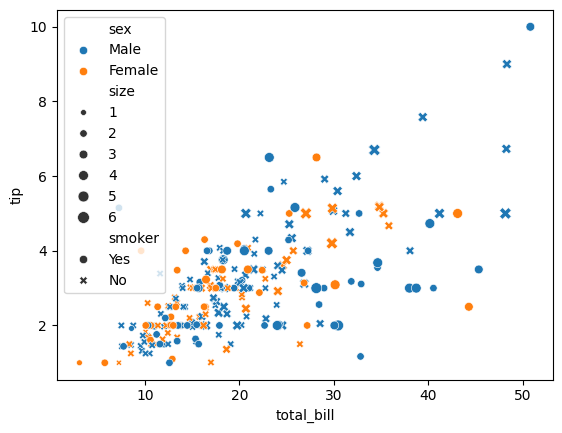

In [16]:
sns.scatterplot(x=tips['total_bill'],y=tips['tip'],hue=tips['sex'],style=tips['smoker'],size=tips['size'])

<Axes: xlabel='total_bill', ylabel='tip'>

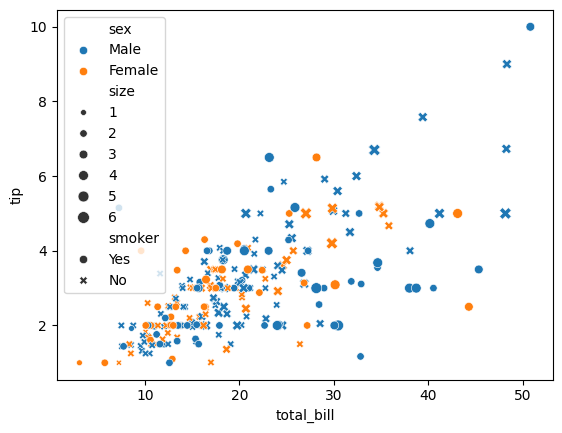

In [17]:
sns.scatterplot(
    data=tips,
    x='total_bill',
    y='tip',
    hue='sex',
    style='smoker',
    size='size'
)

<Axes: xlabel='Pclass', ylabel='Fare'>

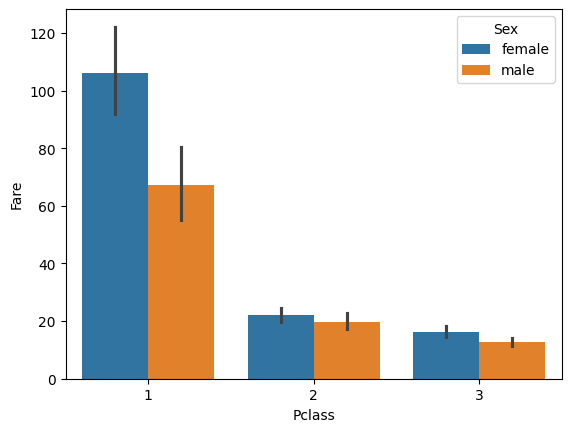

In [18]:
sns.barplot(x=titanic['Pclass'],y=titanic['Fare'],hue=titanic['Sex'])

<Axes: xlabel='Sex', ylabel='Age'>

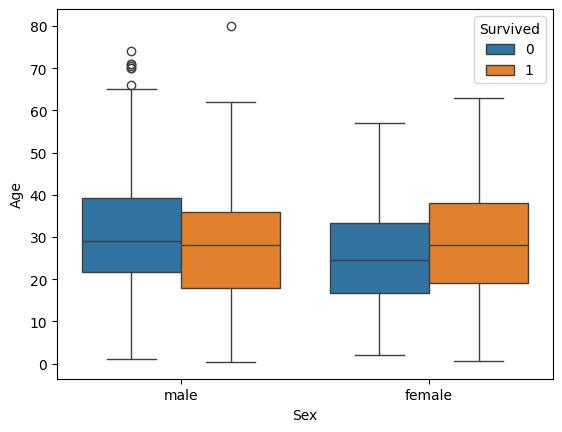

In [19]:
sns.boxplot(x=titanic['Sex'],y=titanic['Age'],hue=titanic['Survived'])

<Axes: xlabel='Age', ylabel='Density'>

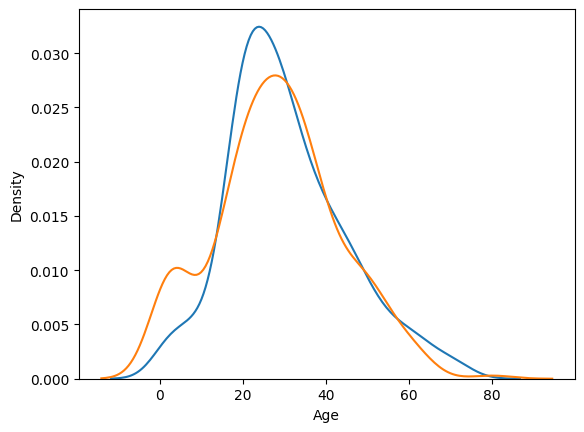

In [25]:
sns.kdeplot(
    data=titanic[titanic['Survived'] == 0],
    x='Age',
    label='Did not survive'
)

sns.kdeplot(
    data=titanic[titanic['Survived'] == 1],
    x='Age',
    label='Survived'
)


<Axes: xlabel='Survived', ylabel='Pclass'>

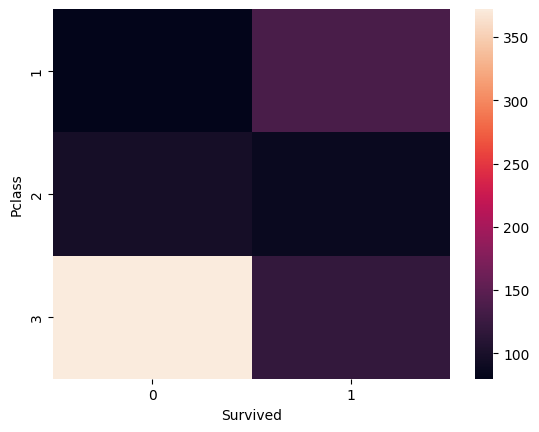

In [26]:
sns.heatmap(pd.crosstab(titanic['Pclass'],titanic['Survived']))

In [28]:
titanic.groupby('Sex')['Survived'].mean() * 100

Sex
female    74.203822
male      18.890815
Name: Survived, dtype: float64

In [29]:
pd.crosstab(titanic['SibSp'],titanic['Survived'])

Survived,0,1
SibSp,,
0,398,210
1,97,112
2,15,13
3,12,4
4,15,3
5,5,0
8,7,0


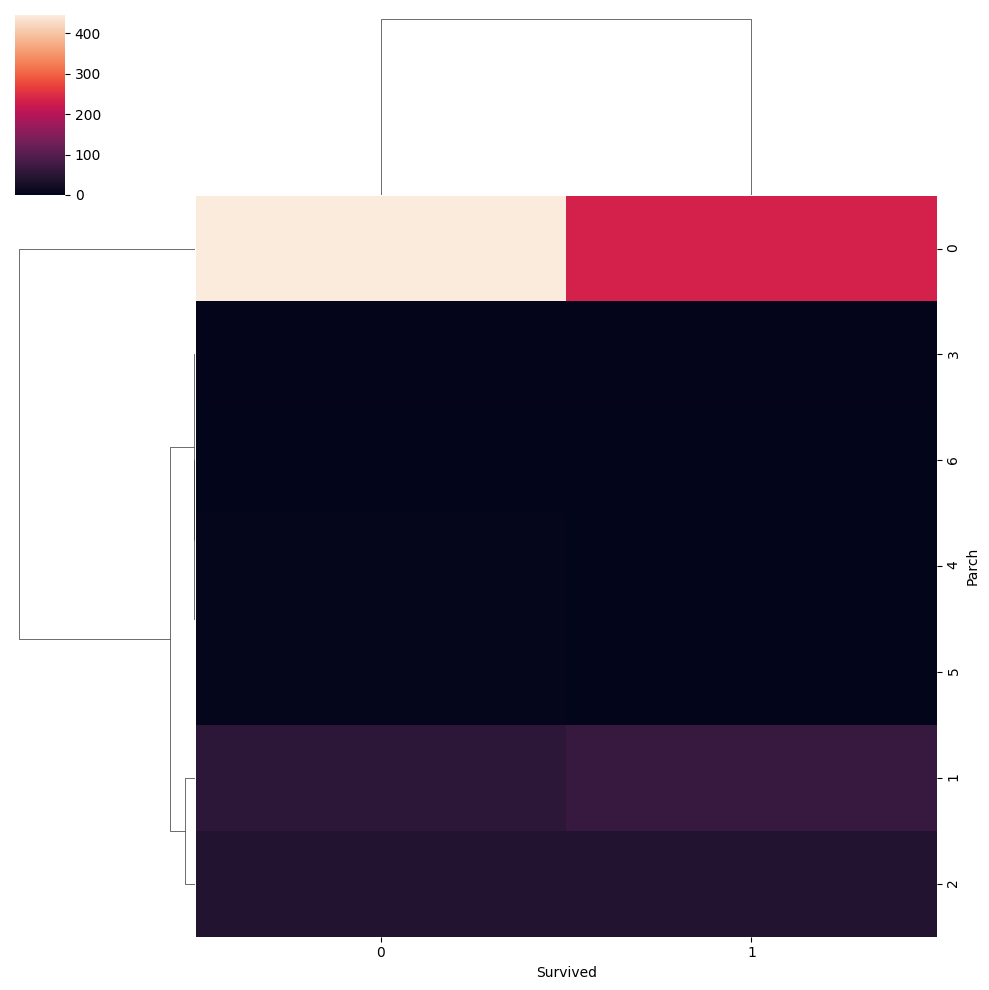

In [30]:
sns.clustermap(pd.crosstab(titanic['Parch'],titanic['Survived']))

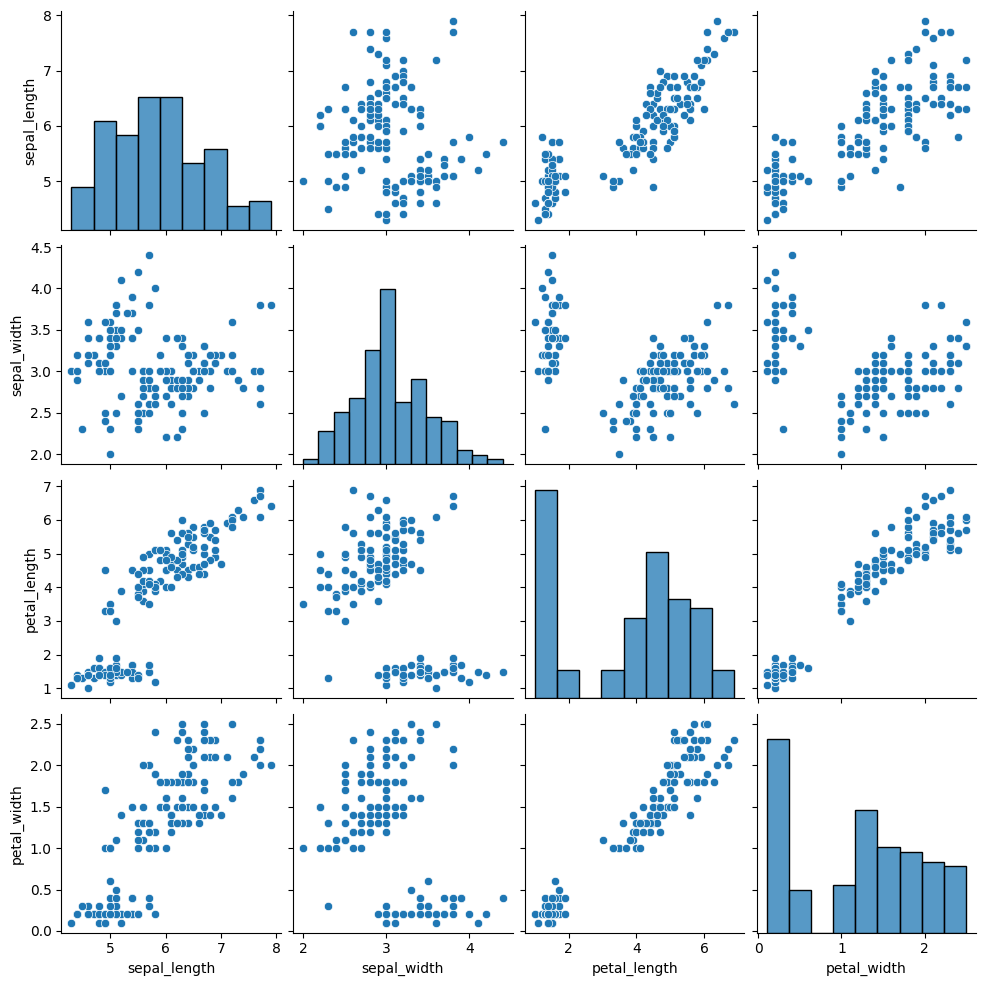

In [32]:
sns.pairplot(iris)

In [33]:
flights.head()

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121


In [39]:
nw=flights.groupby('year').sum(numeric_only=True).reset_index()

In [40]:
nw

,year,passengers
0,1949,1520
1,1950,1676
2,1951,2042
3,1952,2364
4,1953,2700
5,1954,2867
6,1955,3408
7,1956,3939
8,1957,4421
9,1958,4572


<Axes: xlabel='year', ylabel='passengers'>

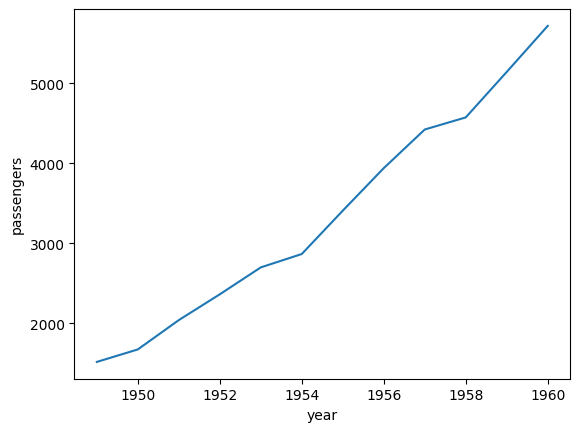

In [50]:
sns.lineplot(data=nw,x='year',y='passengers')

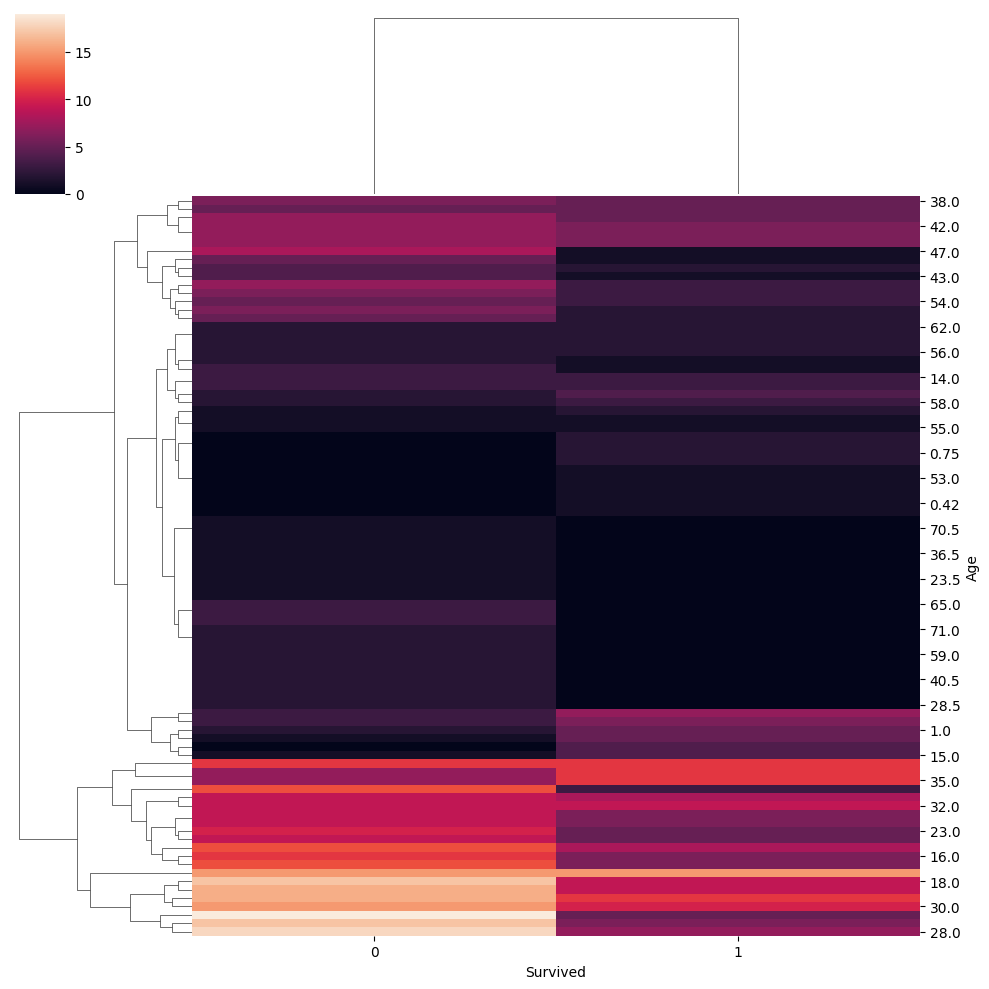

In [51]:
sns.clustermap(pd.crosstab(titanic['Age'],titanic['Survived']))

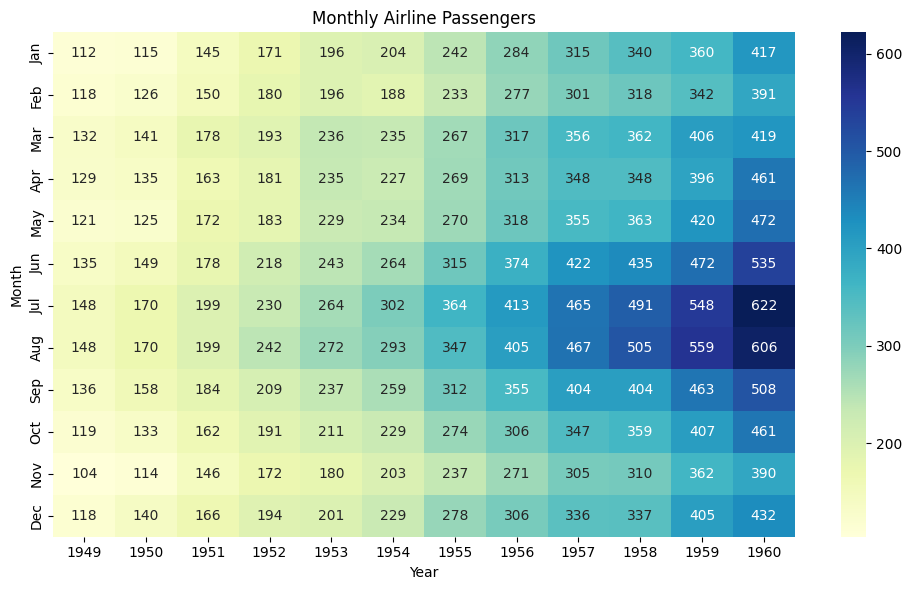

In [55]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
sns.heatmap(
    flights.pivot_table(values='passengers', index='month', columns='year'),
    cmap='YlGnBu',
    annot=True,
    fmt='g'
)
plt.title('Monthly Airline Passengers')
plt.xlabel('Year')
plt.ylabel('Month')
plt.tight_layout()
plt.show()